###**Imports**

In [ ]:
#Data Handling
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

#Statistics
from scipy.stats import pointbiserialr, chi2_contingency
from scipy.stats.contingency import association

#Preprocessing
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from category_encoders import TargetEncoder

#Feature Selection
from sklearn.feature_selection import RFE, SelectFromModel

#Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier

#Assessment
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_validate
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

RANDOM_STATE = 42

pd.set_option('display.max_columns', None)

sns.set_theme(style="whitegrid")
PLOT_BLUE, PLOT_ORANGE = "#1779A8", "#C96A00"
FIGSIZE = (10, 6)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


###**Datasets Import**

In [26]:
clients = pd.read_csv('/content/drive/MyDrive/Trabalho - Machine Learning/Datasets/clientes.csv', sep=',')
test = pd.read_csv('/content/drive/MyDrive/Trabalho - Machine Learning/Datasets/test.csv', sep=',', parse_dates = ['purchase_date'])
train = pd.read_csv('/content/drive/MyDrive/Trabalho - Machine Learning/Datasets/train.csv', sep=',', parse_dates = ['purchase_date'])
sample_submission = pd.read_csv('/content/drive/MyDrive/Trabalho - Machine Learning/Datasets/sample_submission.csv', sep=',')

### 1. Dataset Visualization

First we're going to take a look at each of our datasets and their shapes.

#### 1.1. Clients Dataset

In [27]:
display(clients.head().T)
print(f"Shape do dataset: {clients.shape}")
clients.info()

,0,1,2,3,4
customer_id,842570,770941,827053,494648,429291
country_or_region,Country CT11: Land of The Final Version,Country CT9: Land of The Final Version,Country CT10: Land of The Final Version,Country CT10: Land of The Final Version,Country CT10: Land of The Final Version
commercial_region,Region RG37: We Will See Later,NaN,Region RG17: We Will See Later,Region RG17: We Will See Later,Region RG17: We Will See Later
island,NaN,NaN,Island IS2: The Pivot Archipelago,Island IS2: The Pivot Archipelago,Island IS2: The Pivot Archipelago
municipality,NaN,NaN,Municipality MU14: Council of Last Minute Edits,Municipality MU14: Council of Last Minute Edits,Municipality MU14: Council of Last Minute Edits
city,City CY417: Missing Cell Port,NaN,NaN,NaN,NaN
postal_area,NaN,NaN,Postal area PA271: Hidden Sheet Sector,Postal area PA271: Hidden Sheet Sector,Postal area PA271: Hidden Sheet Sector
postal_code,Postal code PC828: #REF! Delivery Route,Postal code PC56: #REF! Delivery Route,Postal code PC827: #REF! Delivery Route,Postal code PC826: #REF! Delivery Route,Postal code PC826: #REF! Delivery Route
street,NaN,NaN,Street ST170: PowerPoint New Walk,NaN,NaN
address,Address AD1120: Cell Without a Home,Address AD62: Cell Without a Home,Address AD449: Cell Without a Home,Address AD454: Cell Without a Home,Address AD453: Cell Without a Home


Shape do dataset: (1143, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          1143 non-null   int64  
 1   country_or_region    1143 non-null   object 
 2   commercial_region    1029 non-null   object 
 3   island               565 non-null    object 
 4   municipality         984 non-null    object 
 5   city                 597 non-null    object 
 6   postal_area          1072 non-null   object 
 7   postal_code          973 non-null    object 
 8   street               545 non-null    object 
 9   address              1137 non-null   object 
 10  customer_type        0 non-null      float64
 11  company_name         1143 non-null   object 
 12  customer_since_year  1143 non-null   int64  
dtypes: float64(1), int64(2), object(10)
memory usage: 116.2+ KB


Some conclusions on the clients dataset:
- We have 1143 rows and 13 columns;
- We have 3 different datatypes: objects (10), integers (2) and float (1);
- The column "customer_type" is totally empty;
- The columns "comercial_region", "island", "municipality", "city", "postal_area", "postal_code", "street" and "address" all present missing values.

#### 1.2. Test Dataset

In [28]:
display(test.head().T)
print(f"Shape do dataset: {test.shape}")
test.info()

,0,1,2,3,4
Total a Pagar,286.37,1949.25,2738.71,726.98,670.76
Total Bruto,582.05,1725.0,4114.83,591.04,555.49
Total Liquido,232.82,1725.0,2738.71,591.04,545.33
Total Imp_,53.55,224.25,0.0,135.94,125.43
Total Portes,0.0,0.0,0.0,0.0,0.0
Total Desc_ Global,0.0,0.0,0.0,0.0,0.0
Total Desc_ Linha,349.23,0.0,1376.12,0.0,10.16
Custo,104.409267,0.0,1019.466586,341.649008,326.715748
N_ Detalhes,22,1,99,39,13
invoice_count_current_purchase,1,1,1,2,1


Shape do dataset: (986, 38)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 986 entries, 0 to 985
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   Total a Pagar                   986 non-null    float64       
 1   Total Bruto                     986 non-null    float64       
 2   Total Liquido                   986 non-null    float64       
 3   Total Imp_                      986 non-null    float64       
 4   Total Portes                    986 non-null    float64       
 5   Total Desc_ Global              986 non-null    float64       
 6   Total Desc_ Linha               986 non-null    float64       
 7   Custo                           986 non-null    float64       
 8   N_ Detalhes                     986 non-null    int64         
 9   invoice_count_current_purchase  986 non-null    int64         
 10  days_since_previous_purchase    934 non-null  

Some conclusion on the test dataset:
- There are 986 rows and 38 columns;
- Of those 38 columns: 21 present data as float, 10 present it as integers and 7 present it as objects;
- Of those 38 columns, the following present missing values: "days_since_previous_purchase", "prior_mean_purchase_value", "prior_std_purchase_value", "prior_min_purchase_value", "prior_max_purchase_value", "prior_mean_gap_days", "prior_std_gap_days", "spend_365d", "payment_type", "salesperson", "transport_method", "warehouse";

#### 1.3. Train Dataset

In [29]:
display(train.head().T)
print(f"Shape do dataset: {train.shape}")
train.info()

,0,1,2,3,4
Total a Pagar,558.11,978.8,10.33,856.83,1616.1
Total Bruto,510.9,830.02,12.0,696.61,1488.85
Total Liquido,453.75,795.77,8.4,696.61,1313.9
Total Imp_,104.36,183.03,1.93,160.22,302.2
Total Portes,0.0,0.0,0.0,0.0,0.0
Total Desc_ Global,0.0,0.0,0.0,0.0,0.0
Total Desc_ Linha,57.15,34.25,3.6,0.0,174.95
Custo,153.099911,472.943134,6.097485,408.167275,485.401864
N_ Detalhes,4.0,32.0,1.0,9.0,33.0
invoice_count_current_purchase,1.0,1.0,1.0,1.0,1.0


Shape do dataset: (6534, 39)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6534 entries, 0 to 6533
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   Total a Pagar                   6469 non-null   float64       
 1   Total Bruto                     6469 non-null   float64       
 2   Total Liquido                   6469 non-null   float64       
 3   Total Imp_                      6469 non-null   float64       
 4   Total Portes                    6469 non-null   float64       
 5   Total Desc_ Global              6469 non-null   float64       
 6   Total Desc_ Linha               6469 non-null   float64       
 7   Custo                           6469 non-null   float64       
 8   N_ Detalhes                     6469 non-null   float64       
 9   invoice_count_current_purchase  6469 non-null   float64       
 10  repeat_purchase_90d             6534 non-nu

Some conclusions on the train dataset:
- The dataset has 6534 rows and 39 columns;
- Of those 39 columns: 29 present data as float, 3 as integers and 7 as objects;
- Of the 39 columns of the dataset only 3 don't present missing values: "repeat_purchase_90d", "customer_id" and "ID";

#### 1.4. Sample_submission Dataset

In [30]:
display(sample_submission.head().T)
print(f"Shape do dataset: {sample_submission.shape}")
sample_submission.info()

,0,1,2,3,4
ID,10000006,10000008,10000010,10000020,10000025
repeat_purchase_90d,1,1,1,0,1


Shape do dataset: (986, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 986 entries, 0 to 985
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ID                   986 non-null    int64
 1   repeat_purchase_90d  986 non-null    int64
dtypes: int64(2)
memory usage: 15.5 KB


Some conslusions on the sample_submission dataset:
- We have 986 rows and 2 columns:
- The ID column corresponds to the ID of the purchase;
- The repeat purchase column is our target and it's binary: 1 = the customer will repeat the purchase; 0 = the customer won't repeat the purchase;

### 2. Exploratory Data Analysis

#### 2.1. Target Distribution

Distribuição do Target em número absolutos: repeat_purchase_90d
1    3654
0    2880
Name: count, dtype: int64
Distribuição do Target em percentagens: repeat_purchase_90d
1    55.922865
0    44.077135
Name: proportion, dtype: float64


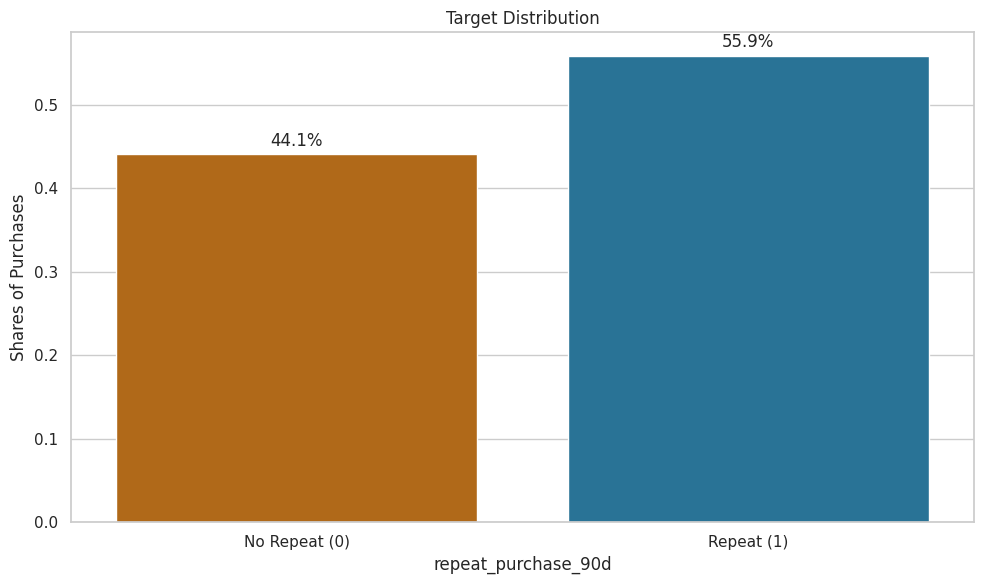

In [31]:
print(f"Distribuição do Target em número absolutos: {train['repeat_purchase_90d'].value_counts()}")
print(f"Distribuição do Target em percentagens: {train['repeat_purchase_90d'].value_counts(normalize = True)*100}")

target_share = train['repeat_purchase_90d'].value_counts(normalize = True).sort_index()

fig, ax = plt.subplots(figsize = FIGSIZE)
labels = ["No Repeat (0)", "Repeat (1)"]
sns.barplot(x=["No Repeat (0)", "Repeat (1)"], y = target_share.values, hue = labels, palette=[PLOT_ORANGE,PLOT_BLUE], legend=False, ax=ax)

for a,b in enumerate(target_share.values):
    ax.text(a,b + 0.01,f"{b:.1%}", ha='center')
ax.set(xlabel = "repeat_purchase_90d", ylabel = "Shares of Purchases", title = "Target Distribution")

plt.tight_layout()
plt.show()

Some conclusions about the target:
- The target has no missing values;
- Around 55.9% of the purchases are repeated within 90 days;
- Around 44.1% of the purchases aren't repeated within 90 days;
- Both classes are well represented;

#### 2.2. Missing Values - Train Dataset

In [32]:
rows_with_null = train.isna().any(axis=1)
null_per_column = train.isna().sum()

pd.Series({
    "rows with null": f"{rows_with_null.sum():,} of {len(train):,} ({100*rows_with_null.mean():.2f}%)",
    "columns with null": f"{(null_per_column > 0).sum()} of {train.shape[1]}",
    "null cells": f"{train.isna().sum().sum():,}",
    "worst column": f"{null_per_column.idxmax()} ({null_per_column.max()} nulls)",
}).to_frame("Missing Values in Train")

,Missing Values in Train
rows with null,"2,605 of 6,534 (39.87%)"
columns with null,36 of 39
null cells,"9,818"
worst column,prior_std_gap_days (1478 nulls)


In [33]:
missing_table = pd.DataFrame(
    {"missing": null_per_column,
     "missing (%)": (100*train.isna().mean()).round(2)}
)

missing_table = missing_table[missing_table['missing']>0].sort_values('missing', ascending = False)
missing_table

,missing,missing (%)
prior_std_gap_days,1478,22.62
prior_mean_gap_days,1308,20.02
prior_std_purchase_value,1113,17.03
prior_mean_purchase_value,862,13.19
days_since_previous_purchase,861,13.18
prior_max_purchase_value,668,10.22
prior_min_purchase_value,668,10.22
transport_method,261,3.99
warehouse,260,3.98
payment_type,260,3.98


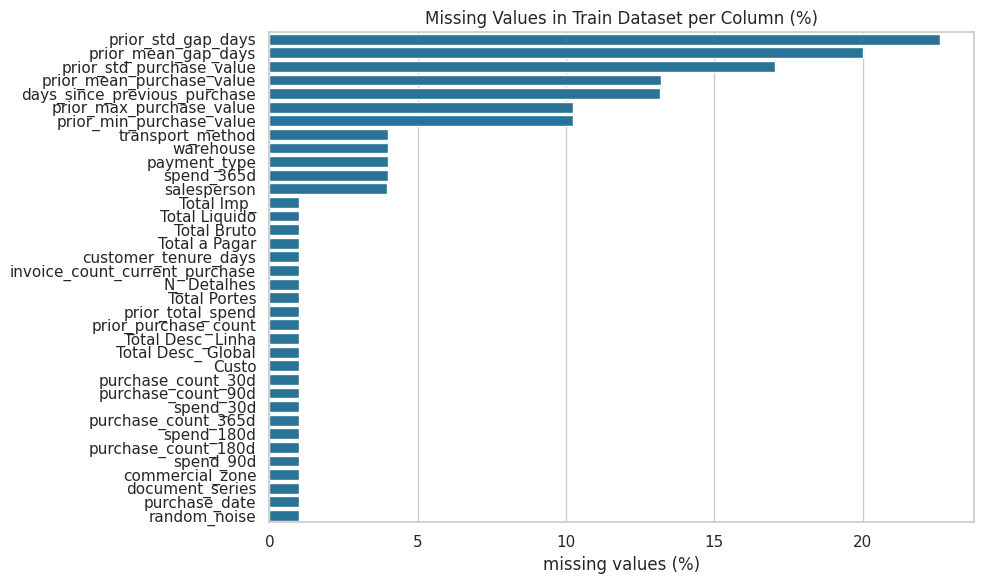

In [34]:
plot_missing_train = missing_table.reset_index().rename(columns = {'index': 'column'})

fig, ax = plt.subplots(figsize = FIGSIZE)
sns.barplot(plot_missing_train, x = 'missing (%)', y = 'column', color = PLOT_BLUE, ax = ax)
ax.set(xlabel = "missing values (%)", ylabel = "", title = "Missing Values in Train Dataset per Column (%)")
plt.tight_layout()
plt.show()

In [35]:
for column in ['days_since_previous_purchase', 'prior_mean_gap_days', 'prior_std_gap_days']:
  display(pd.crosstab(train['prior_purchase_count'].clip(upper = 3), train[column].isna(), rownames = ['prior purchases'], colnames = [f"{column} is missing"]))

days_since_previous_purchase is missing,False,True
prior purchases,,
0.0,0,603
1.0,426,19
2.0,345,20
3.0,4902,154


prior_mean_gap_days is missing,False,True
prior purchases,,
0.0,0,603
1.0,0,445
2.0,344,21
3.0,4882,174


prior_std_gap_days is missing,False,True
prior purchases,,
0.0,0,603
1.0,0,445
2.0,0,365
3.0,5056,0


Some conclusions:


#### 2.3. Temporal and Customer Structure

In [36]:
pd.DataFrame({
    "first purchase": [train["purchase_date"].min(), test["purchase_date"].min()],
    "last purchase": [train["purchase_date"].max(), test["purchase_date"].max()],
}, index=["train", "test"])

,first purchase,last purchase
train,2015-07-11,2025-02-15
test,2025-05-24,2026-10-06


In [37]:
gap = (test["purchase_date"].min() - train["purchase_date"].max()).days
print(f"Days between the end of train and the start of test: {gap}")

Days between the end of train and the start of test: 98


Some conclusions:
- Train covers purchases from **July 2015 to February 2025**, while test covers **May 2025 to October 2026**;
- The test set lies entirely after the train period;
- There is a gap of 98 days between the last train purchase and the first test purchase;
- Because of this, a random split for validation would mix past and future rows and give an optimistic score. Validation should respect time order (e.g. training on earlier purchases and validating on the most recent ones);

In [38]:
rows_per_customer = train.groupby("customer_id").size()

print(f"Distinct customers in train: {train['customer_id'].nunique()}")
print(f"Distinct customers in test: {test['customer_id'].nunique()}")
rows_per_customer.describe().round(1).to_frame("rows per customer (train)")

Distinct customers in train: 610
Distinct customers in test: 206


,rows per customer (train)
count,610.0
mean,10.7
std,20.0
min,1.0
25%,1.0
50%,4.0
75%,12.0
max,277.0


In [39]:
common = test["customer_id"].isin(train["customer_id"])

print(f"Test rows whose customer also appears in train: {common.mean():.1%}")
print(f"Test customers already seen in train: {test.loc[common, 'customer_id'].nunique()} of {test['customer_id'].nunique()}")

Test rows whose customer also appears in train: 94.5%
Test customers already seen in train: 184 of 206


Some conclusions:
- The 6,534 train rows come from only **610 distinct customers**, so the same customer appears many times: on average 10.7 purchases per customer (median 4, maximum 277);
- The distribution is very uneven: a quarter of customers have a single purchase, while a few customers account for hundreds of rows;
- Rows are therefore **not independent**: purchases from the same customer share the same history and behaviour;
- **94.5% of test rows** belong to customers already seen in train (184 of 206 test customers). The task is mostly to predict the **future behaviour of known customers**, not of new ones;
- This supports a **time-based validation**: training on earlier purchases and validating on later ones reproduces what the model faces in test (the same customers, later in time);

In [40]:
by_year = (train.groupby(train["purchase_date"].dt.year)["repeat_purchase_90d"].agg(rows="size", repeat_rate="mean").round(3))
by_year.index = by_year.index.astype(int)
by_year

,rows,repeat_rate
purchase_date,,
2015,335,0.534
2016,420,0.514
2017,670,0.633
2018,716,0.538
2019,646,0.522
2020,670,0.594
2021,782,0.549
2022,628,0.481
2023,767,0.581


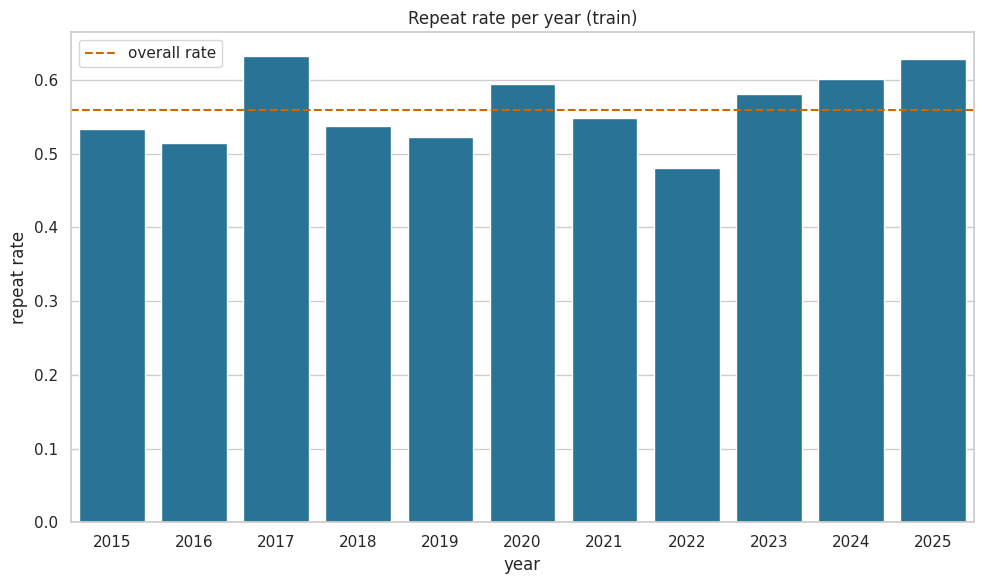

In [41]:
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.barplot(x=by_year.index.astype(str), y=by_year["repeat_rate"], color=PLOT_BLUE, ax=ax)
ax.axhline(train["repeat_purchase_90d"].mean(), color=PLOT_ORANGE, linestyle="--", label="overall rate")
ax.set(xlabel="year", ylabel="repeat rate", title="Repeat rate per year (train)")
ax.legend()
plt.tight_layout()
plt.show()

Some conclusions:
- The repeat rate moves between **48% (2022) and 63% (2017)**, oscillating around the overall rate of 56% with **no consistent upward or downward trend** over the whole period;
- This suggests that the relation between customer behaviour and repeat purchase is reasonably stable, so what the model learns from past years should still hold in the test period;
- However, the **most recent years (2023-2025) are all above the overall rate** (58-63%). Since test comes right after train, the share of repeat purchases in test may be slightly higher than the training average. Validating on the most recent purchases will reflect this better than a random split;
- **2015** (starting in July) and especially **2025** (only 78 rows, up to February) are partial years, so their rates are less reliable, in particular 2025;

#### 2.4. Duplicates and Identifiers



In [42]:
train_no_id = train.drop(columns="ID")
test_no_id = test.drop(columns="ID")

print("ID unique in train:", train["ID"].is_unique)
print("ID unique in test:", test["ID"].is_unique)
print("exact duplicate rows in train (ignoring ID):", train_no_id.duplicated().sum())
print("exact duplicate rows in test (ignoring ID):", test_no_id.duplicated().sum())

ID unique in train: True
ID unique in test: True
exact duplicate rows in train (ignoring ID): 10
exact duplicate rows in test (ignoring ID): 0


In [43]:
empty_rows = train["purchase_date"].isna()
print("duplicates once the empty rows are removed:", train_no_id[empty_rows == False].duplicated().sum())

duplicates once the empty rows are removed: 0


Some conclusions:
- `ID` is **unique in both train and test**, so it identifies each purchase. It is used to match predictions with `sample_submission`, but it carries no information about the customer and is **not used as a feature**;
- Ignoring `ID`, train has **10 duplicated rows** and test has none;
- Once the 65 nearly empty rows are set aside, **no duplicates remain**. The duplicates are only empty rows that look identical because they keep just `customer_id` and the target, not repeated purchases;
- No real purchase needs to be removed for being duplicated; the issue is reduced to the 65 empty rows, which will be handled in the cleaning step;

In [44]:
print("customer_id unique in clients:", clients["customer_id"].is_unique)
print("every train customer is in clients:", train["customer_id"].isin(clients["customer_id"]).all())
print("every test customer is in clients:", test["customer_id"].isin(clients["customer_id"]).all())

customer_id unique in clients: True
every train customer is in clients: True
every test customer is in clients: True


In [45]:
clients_profile = pd.DataFrame({"missing (%)": (100 * clients.isna().mean()).round(1),"unique values": clients.nunique(),})
clients_profile

,missing (%),unique values
customer_id,0.0,1143
country_or_region,0.0,11
commercial_region,10.0,37
island,50.6,10
municipality,13.9,183
city,47.8,417
postal_area,6.2,271
postal_code,14.9,828
street,52.3,511
address,0.5,1120


Some Conclusions:
- The **join is safe**: `customer_id` is unique in `clients`, and every customer in train and test is present there, so no purchase would be duplicated or lost;
- `clients` describes 1,143 customers, more than the ones appearing in train and test, so only part of the table would be used;
- Several columns are **not useful as features**:
  - `customer_type` is **100% empty**;
  - `company_name` (1,141 values) and `address` (1,120 values) have practically **one value per customer**, so they act as identifiers;
  - `island`, `city` and `street` are **about 50% empty**;
  - `postal_code` (828 values) and `municipality` (183 values) have very **high cardinality** for so few customers;
-The only columns worth testing are the well-filled, low-cardinality ones: **`country_or_region`**, **`commercial_region`** and **`customer_since_year`**. `customer_since_year` may be redundant with `customer_tenure_days`, which already exists in train. Whether to join them will be decided by comparing results in validation;

In [46]:
print("correlation with the target:")
print(train[["customer_id", "random_noise"]].corrwith(train["repeat_purchase_90d"]).round(4))

correlation with the target:
customer_id    -0.112
random_noise   -0.012
dtype: float64


In [47]:
train["random_noise"].describe().round(2)

,random_noise
count,6469.00
mean,-0.02
std,1.00
min,-3.53
25%,-0.68
50%,-0.05
75%,0.64
max,4.15


Some conclusions:
- `random_noise` behaves exactly like **randomly generated noise**: mean ≈ 0, standard deviation ≈ 1, roughly symmetric values between -3.5 and 4.2, and a correlation of only **-0.012** with the target. It carries no information and is **excluded**. It is kept in mind as a reference for "no relationship": in feature selection, a variable that does no better than it should be treated with suspicion;
- `customer_id` shows a correlation of **-0.112** with the target, but it is a **label, not a measure**: a higher number says nothing about the customer. The correlation most likely comes from how the numbers were assigned and from a few customers with many purchases, not from customer behaviour;
- Using `customer_id` as a feature would let the model memorise specific customers instead of learning patterns that generalise. The relevant customer information is already captured by the history columns (`prior_*`, purchase counts, recency). `customer_id` is therefore **excluded as a feature**, but kept to identify customers (e.g. for the join with `clients`);
- Together with `ID`, these columns are dropped before modelling;

#### 2.5. Impossible *Values*

In [48]:
numeric_cols = train.select_dtypes(include="number").columns.drop(["ID", "customer_id", "random_noise", "repeat_purchase_90d"])
train[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,925.56,1335.00,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,6469.0,886.15,1327.64,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,6469.0,773.34,1136.36,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,6469.0,152.22,225.26,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,6469.0,1.15,5.84,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,6469.0,0.35,5.12,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,6469.0,112.47,289.99,0.00,0.00,13.13,92.28,4.103440e+03
Custo,6469.0,328.17,519.51,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,6469.0,21.52,27.71,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,6469.0,1.07,0.31,1.00,1.00,1.00,1.00,5.000000e+00


**Conclusions:**

- **Impossible negative values** appear in columns that cannot be negative:
  - `days_since_previous_purchase` and `prior_mean_gap_days` reach **-4 days**;
  - `prior_mean_purchase_value` reaches **-2,478.66** and `spend_365d` reaches **-159,115.18** (a purchase value or a spend cannot be negative).
- **Sentinel values**: `prior_mean_purchase_value` and `spend_365d` reach exactly **1,000,000,000 (1e9)**, far beyond any real value (their 75th percentiles are around 1,100 and 7,000). These are placeholders, not real amounts.
- These few values **distort the statistics**: the mean of `prior_mean_purchase_value` is **2.8 million** while its median is only **725**, and the same happens with `spend_365d` (mean 2.4 million vs median 2,427).
- Even without these errors, the **money and count columns are strongly right-skewed**: means are well above medians (e.g. `Total a Pagar` 926 vs 477, `prior_total_spend` 18,908 vs 6,754), with long tails of large values.
- Some columns are **almost constant**: `Total Portes` and `Total Desc_ Global` are 0 in more than 75% of rows, and `invoice_count_current_purchase` is almost always 1. They are likely to carry little information.

In [50]:
for column in numeric_cols:
    train_neg = (train[column] < 0).sum()
    train_sentinel = (train[column] >= 1e9).sum()
    test_neg = (test[column] < 0).sum()
    test_sentinel = (test[column] >= 1e9).sum()
    if train_neg + train_sentinel + test_neg + test_sentinel > 0:
        print(f"{column:30s} train: {train_neg} negative, {train_sentinel} sentinel | "
              f"test: {test_neg} negative, {test_sentinel} sentinel")

days_since_previous_purchase   train: 16 negative, 0 sentinel | test: 2 negative, 0 sentinel
prior_mean_purchase_value      train: 16 negative, 16 sentinel | test: 2 negative, 2 sentinel
prior_mean_gap_days            train: 16 negative, 0 sentinel | test: 2 negative, 0 sentinel
spend_365d                     train: 15 negative, 15 sentinel | test: 2 negative, 2 sentinel


In [53]:
for column in numeric_cols:
    print(f"{column:30s} min {train[column].min():12.2f}   negative rows {(train[column] < 0).sum():4d}   max {train[column].max():14.2f}   rows at 1e9 {(train[column] >= 1e9).sum():4d}")

Total a Pagar                  min         0.93   negative rows    0   max       22297.21   rows at 1e9    0
Total Bruto                    min         0.83   negative rows    0   max       21578.28   rows at 1e9    0
Total Liquido                  min         0.76   negative rows    0   max       18127.81   rows at 1e9    0
Total Imp_                     min         0.00   negative rows    0   max        4169.40   rows at 1e9    0
Total Portes                   min         0.00   negative rows    0   max         181.06   rows at 1e9    0
Total Desc_ Global             min         0.00   negative rows    0   max         218.49   rows at 1e9    0
Total Desc_ Linha              min         0.00   negative rows    0   max        4103.44   rows at 1e9    0
Custo                          min         0.00   negative rows    0   max        7427.40   rows at 1e9    0
N_ Detalhes                    min         1.00   negative rows    0   max         423.00   rows at 1e9    0
invoice_count_curre

**Some conclusions:**

- Only **4 columns** contain impossible values; all the others have plausible ranges.
- **Negative values** (16 rows each in `days_since_previous_purchase`, `prior_mean_purchase_value` and `prior_mean_gap_days`, 15 in `spend_365d`): days, amounts and spends cannot be negative. Every negative day count is exactly **-4**, which suggests an injected error rather than a natural one.
- **Sentinel values**: 16 rows in `prior_mean_purchase_value` and 15 in `spend_365d` hold exactly **1e9**, a placeholder rather than a real amount.
- Each problem affects only **15-16 rows out of 6,534** (about 0.25%), so these are **isolated errors**, not a systematic issue.
- Since only one cell per row is wrong, the planned treatment is to **set these cells to missing** and impute them later, instead of dropping the whole row.

In [54]:
anomalies = pd.DataFrame({
    "days_since_prev < 0": train["days_since_previous_purchase"] < 0,
    "prior_mean_gap < 0": train["prior_mean_gap_days"] < 0,
    "prior_mean_value < 0": train["prior_mean_purchase_value"] < 0,
    "prior_mean_value = 1e9": train["prior_mean_purchase_value"] >= 1e9,
    "spend_365d < 0": train["spend_365d"] < 0,
    "spend_365d = 1e9": train["spend_365d"] >= 1e9,
})

errors_per_row = anomalies.sum(axis=1)

print("rows with at least one error:", (errors_per_row >= 1).sum())
print("rows with two or more errors:", (errors_per_row >= 2).sum())

rows with at least one error: 94
rows with two or more errors: 0


**Some conclusions:**

- The 94 impossible values (16 + 16 + 16 + 16 + 15 + 15) fall in **94 different rows**: no row has more than one error.
- The errors are therefore **isolated, single-cell errors**, not corrupted rows: in each of these purchases, all the other columns hold valid values.
- Dropping these rows would throw away 94 otherwise correct purchases (about 1.4% of train) because of a single bad cell. The better treatment is to **replace each impossible value with missing** and impute it later, together with the other missing values.
- Since test contains the same kind of errors, this rule (negative or 1e9 → missing) will be applied to both train and test.

In [65]:
expected_mean = train["prior_total_spend"] / train["prior_purchase_count"]

print(f"prior_max > prior_total_spend: {(train["prior_max_purchase_value"] > train["prior_total_spend"] + 0.01).sum()}")
print(f"prior_min > prior_max: {(train["prior_min_purchase_value"] > train["prior_max_purchase_value"]).sum()}")
print(f"prior_mean different from total / count: {((train["prior_mean_purchase_value"] - expected_mean).abs() > 0.05).sum()}")
print(f"purchase_count_30d > purchase_count_90d: {(train["purchase_count_30d"] > train["purchase_count_90d"]).sum()}")
print(f"purchase_count_90d > purchase_count_180d: {(train["purchase_count_90d"] > train["purchase_count_180d"]).sum()}")
print(f"purchase_count_180d > purchase_count_365d: {(train["purchase_count_180d"] > train["purchase_count_365d"]).sum()}")
print(f"days_since_previous_purchase > customer_tenure_days: {(train["days_since_previous_purchase"] > train["customer_tenure_days"]).sum()}")

prior_max > prior_total_spend: 45
prior_min > prior_max: 0
prior_mean different from total / count: 78
purchase_count_30d > purchase_count_90d: 0
purchase_count_90d > purchase_count_180d: 0
purchase_count_180d > purchase_count_365d: 0
days_since_previous_purchase > customer_tenure_days: 0


**Some conclusions:**

- Several rules **always hold**: the minimum never exceeds the maximum, the purchase counts are correctly nested across windows (30d ≤ 90d ≤ 180d ≤ 365d), and the days since the previous purchase never exceed the customer tenure. These columns are reliable.
- `prior_mean_purchase_value` differs from `prior_total_spend / prior_purchase_count` in **78 rows**. 32 of them are the sentinel and negative values already found; the other **46 are hidden errors**: plausible-looking means that do not match the customer's history.
- In **45 rows**, `prior_max_purchase_value` is larger than `prior_total_spend`, which is impossible: a single purchase cannot be worth more than the sum of all purchases.
- These hidden errors could not be seen in the descriptive statistics, because the values lie within normal ranges.
- Treatment:
  - `prior_mean_purchase_value` can be **recomputed exactly** as `prior_total_spend / prior_purchase_count`, which also fixes its sentinel and negative values;
  - the impossible values of `prior_max_purchase_value` will be **set to missing** and imputed.

#### 2.6. Categorical Variables

In [66]:
categorical_cols = train.select_dtypes(include="object").columns

summary = train[categorical_cols].describe().T
summary["top share (%)"] = (100 * summary["freq"] / summary["count"]).astype(float).round(1)
summary

,count,unique,top,freq,top share (%)
payment_type,6274,9,Maybe Tomorrow Payment 7,4565,72.8
salesperson,6275,9,VLOOKUP Master 1,4054,64.6
commercial_zone,6469,5,Decorative Dashboard Zone 4,6260,96.8
transport_method,6273,80,Maybe Tomorrow Delivery 72,1119,17.8
warehouse,6274,2,Final Excel Warehouse 1,6253,99.7
document_series,6469,3,Ctrl Z Series 2,2738,42.3


**Some conclusions:**

- There are **6 categorical variables**, with very different profiles.
- Two are **almost constant**:
  - `warehouse` has only 2 levels, and one of them covers **99.7%** of rows;
  - `commercial_zone` has 5 levels, but one covers **96.8%** of rows.
  They hardly distinguish purchases and are likely to carry little information.
- `transport_method` has **80 levels**, with the most frequent covering only 17.8% of rows. With one-hot encoding it would create about 80 columns, most of them with very few rows. It will need a different treatment (grouping rare levels or another encoding).
- `payment_type` (9 levels, top 72.8%), `salesperson` (9 levels, top 64.6%) and `document_series` (3 levels, top 42.3%) have **few levels and are not dominated by a single one**, so they are the most promising candidates.
- `payment_type`, `salesperson`, `transport_method` and `warehouse` have **around 4% missing values**, and the other two have the 65 missing values of the empty rows.

In [67]:
for column in categorical_cols:
    new_in_test = test[column].isin(train[column]) == False
    new_levels = test.loc[new_in_test, column].dropna().unique()
    if len(new_levels) > 0:
        print(f"{column:20s} {len(new_levels)} new levels in {test[column].isin(new_levels).sum()} test rows: {list(new_levels)}")

payment_type         3 new levels in 3 test rows: ['Maybe Tomorrow Payment 5', 'Maybe Tomorrow Payment 6', 'Maybe Tomorrow Payment 1']
commercial_zone      2 new levels in 209 test rows: ['Decorative Dashboard Zone 1', 'Decorative Dashboard Zone 5']
transport_method     2 new levels in 63 test rows: ['Maybe Tomorrow Delivery 54', 'Maybe Tomorrow Delivery 65']
warehouse            1 new levels in 7 test rows: ['Final Excel Warehouse 2']


**Some conclusions**:
- 4 categorical columns have levels in the test set that never appear in train;
- Most of these levels are rare and only impact a handful of test rows;
- However the exception is **`commercial_zone`**. It's two new zones cover 209 test rows while in train the column is almost constant. So the model will learn little from it and then meet a sizeable block of test rows with zones it has never seen;

In [71]:
for column in categorical_cols:
    by_level = (train.groupby(column)["repeat_purchase_90d"].agg(rows="size", repeat_rate="mean").sort_values("rows", ascending=False).round(3))
    print(column)
    print(by_level.head(10).to_string())
    print()

payment_type
                           rows  repeat_rate
payment_type                                
Maybe Tomorrow Payment 7   4565        0.527
Maybe Tomorrow Payment 12   991        0.543
Maybe Tomorrow Payment 9    502        0.950
Maybe Tomorrow Payment 10   134        0.403
Maybe Tomorrow Payment 8     40        0.325
Maybe Tomorrow Payment 2     21        0.524
Maybe Tomorrow Payment 4      9        0.444
Maybe Tomorrow Payment 11     8        0.625
Maybe Tomorrow Payment 3      4        0.500

salesperson
                  rows  repeat_rate
salesperson                        
VLOOKUP Master 1  4054        0.624
VLOOKUP Master 4  1461        0.394
VLOOKUP Master 9   384        0.547
VLOOKUP Master 7   201        0.483
VLOOKUP Master 2   123        0.602
VLOOKUP Master 3    30        0.367
VLOOKUP Master 6    12        0.000
VLOOKUP Master 5     7        0.429
VLOOKUP Master 8     3        1.000

commercial_zone
                             rows  repeat_rate
commercial_zone    

#### 2.7. Distributions and Relationships

In [73]:
clean = train[numeric_cols].where((train[numeric_cols] >= 0) & (train[numeric_cols] < 1e9))

skewness = clean.skew().sort_values(ascending=False).round(2)
print(skewness.to_frame("skew").to_string())

                                 skew
Total Desc_ Global              27.46
prior_max_purchase_value        21.34
prior_mean_purchase_value       21.20
Total Portes                    19.55
spend_365d                      18.55
prior_mean_gap_days              9.31
prior_std_gap_days               7.77
days_since_previous_purchase     6.53
invoice_count_current_purchase   6.44
Total Desc_ Linha                5.92
prior_min_purchase_value         5.90
spend_30d                        5.50
Total Imp_                       4.84
Custo                            4.61
Total Bruto                      4.31
Total a Pagar                    4.21
Total Liquido                    4.15
spend_90d                        3.72
prior_purchase_count             3.54
purchase_count_90d               3.34
purchase_count_30d               3.31
purchase_count_180d              3.22
purchase_count_365d              3.20
spend_180d                       3.15
prior_total_spend                3.08
N_ Detalhes 

In [75]:
zero_share = (100 * (clean == 0).mean()).sort_values(ascending=False).round(1)
print(zero_share.head(10).to_frame("zeros (%)").to_string())

                     zeros (%)
Total Desc_ Global        97.3
Total Portes              82.9
purchase_count_30d        66.5
spend_30d                 66.5
purchase_count_90d        44.2
spend_90d                 44.2
Total Desc_ Linha         37.4
spend_180d                21.6
purchase_count_180d       21.6
purchase_count_365d       12.9


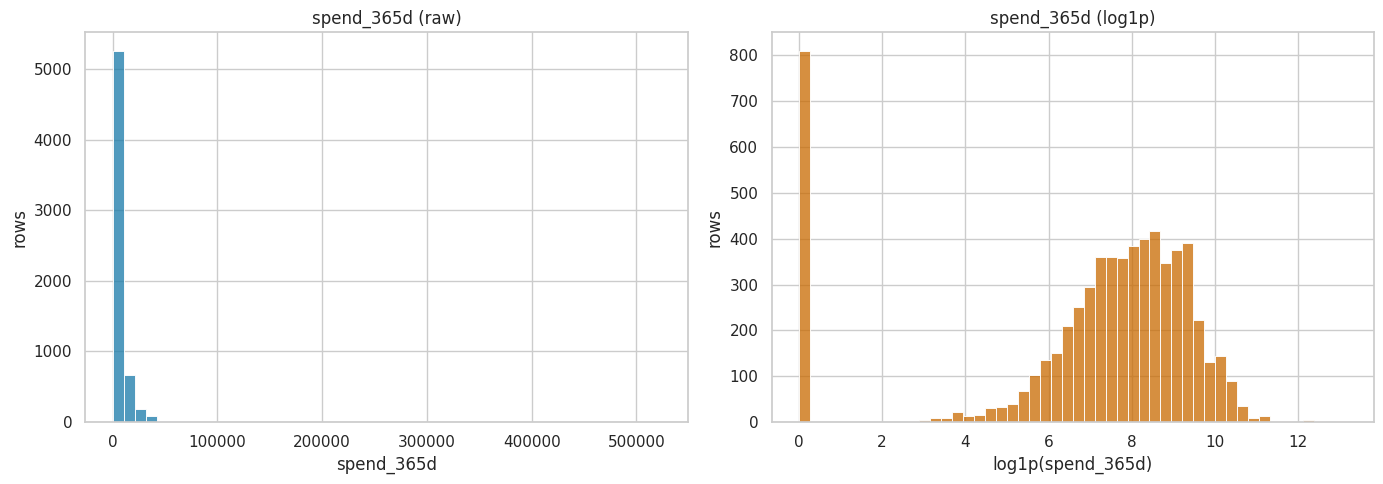

In [76]:
column = "spend_365d"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(clean[column].dropna(), bins=50, color=PLOT_BLUE, ax=axes[0])
axes[0].set(title=f"{column} (raw)", xlabel=column, ylabel="rows")
sns.histplot(np.log1p(clean[column].dropna()), bins=50, color=PLOT_ORANGE, ax=axes[1])
axes[1].set(title=f"{column} (log1p)", xlabel=f"log1p({column})", ylabel="rows")
plt.tight_layout()
plt.show()

In [77]:
by_class = clean.groupby(train["repeat_purchase_90d"]).median().T.round(1)
by_class.columns = ["no repeat (0)", "repeat (1)"]
by_class["ratio 1/0"] = (by_class["repeat (1)"] / by_class["no repeat (0)"]).round(2)
print(by_class.sort_values("ratio 1/0").to_string())

                                no repeat (0)  repeat (1)  ratio 1/0
days_since_previous_purchase            105.0        37.0       0.35
prior_min_purchase_value                 88.1        45.5       0.52
prior_mean_gap_days                     101.8        55.8       0.55
prior_std_gap_days                       65.1        43.6       0.67
N_ Detalhes                              12.0        10.0       0.83
Custo                                   157.5       147.9       0.94
invoice_count_current_purchase            1.0         1.0       1.00
Total a Pagar                           443.1       517.5       1.17
Total Liquido                           362.2       422.0       1.17
prior_mean_purchase_value               632.4       789.9       1.25
Total Bruto                             389.9       493.2       1.26
Total Imp_                               69.8        88.8       1.27
customer_tenure_days                    781.0      1032.0       1.32
prior_std_purchase_value          

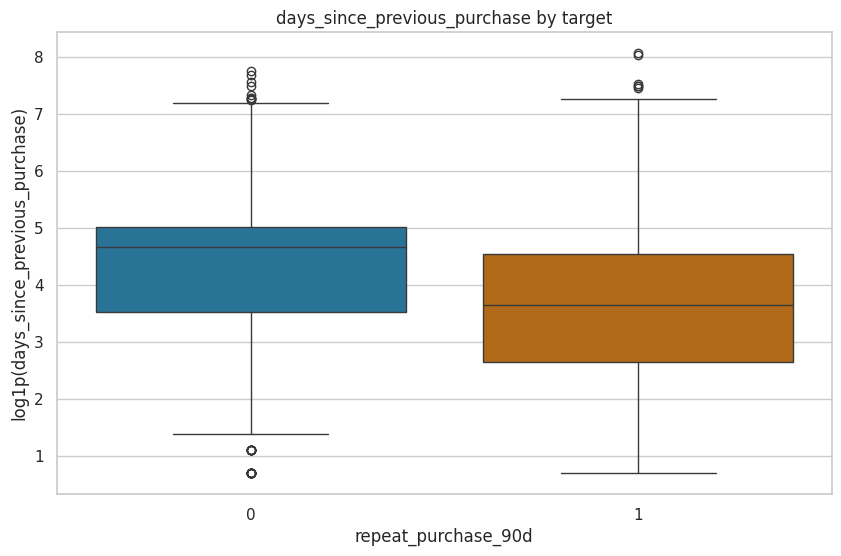

In [78]:
column = "days_since_previous_purchase"

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.boxplot(x=train["repeat_purchase_90d"], y=np.log1p(clean[column]),
            hue=train["repeat_purchase_90d"], palette=[PLOT_BLUE, PLOT_ORANGE], legend=False, ax=ax)
ax.set(title=f"{column} by target", xlabel="repeat_purchase_90d", ylabel=f"log1p({column})")
plt.show()

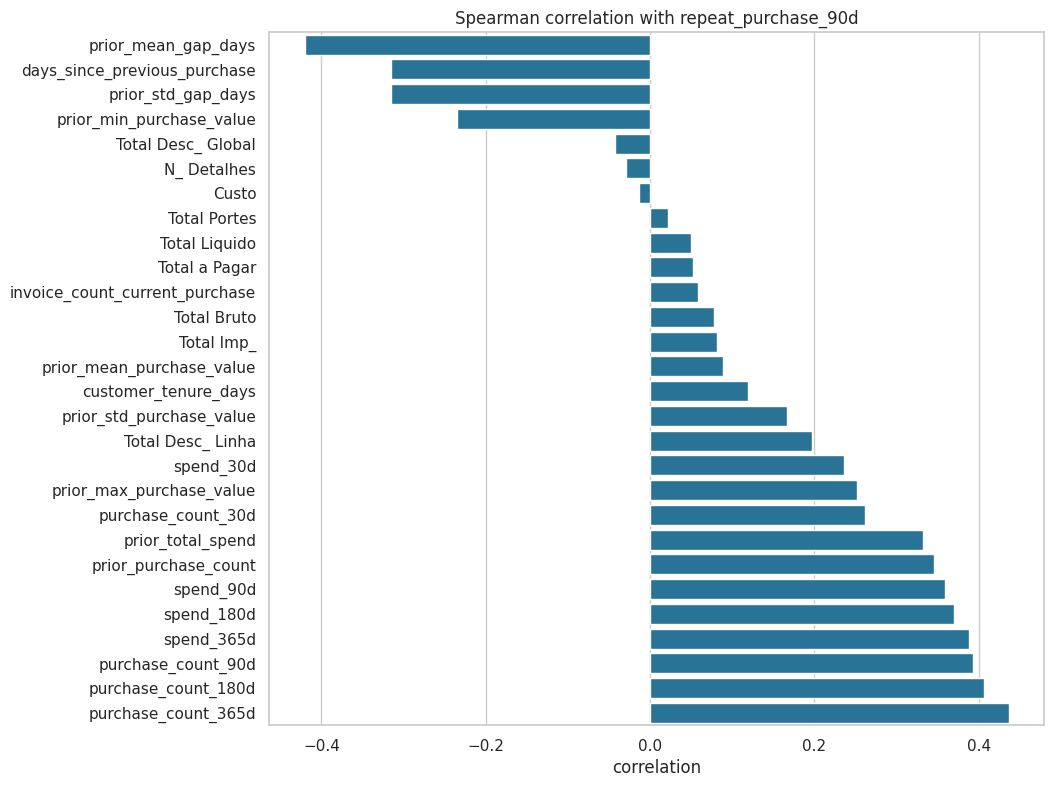

In [79]:
target_corr = clean.corrwith(train["repeat_purchase_90d"], method="spearman").sort_values()

fig, ax = plt.subplots(figsize=(10, 9))
sns.barplot(x=target_corr.values, y=target_corr.index, color=PLOT_BLUE, ax=ax)
ax.set(title="Spearman correlation with repeat_purchase_90d", xlabel="correlation", ylabel="")
plt.show()

In [80]:
corr = clean.corr(method="spearman")

for i, first in enumerate(corr.columns):
    for second in corr.columns[i + 1:]:
        if abs(corr.loc[first, second]) > 0.9:
            print(f"{first:32s} {second:32s} {corr.loc[first, second]:.3f}")

Total a Pagar                    Total Bruto                      0.991
Total a Pagar                    Total Liquido                    1.000
Total Bruto                      Total Liquido                    0.991
prior_purchase_count             prior_total_spend                0.903
prior_std_purchase_value         prior_max_purchase_value         0.923
purchase_count_30d               spend_30d                        0.965
purchase_count_90d               spend_90d                        0.909


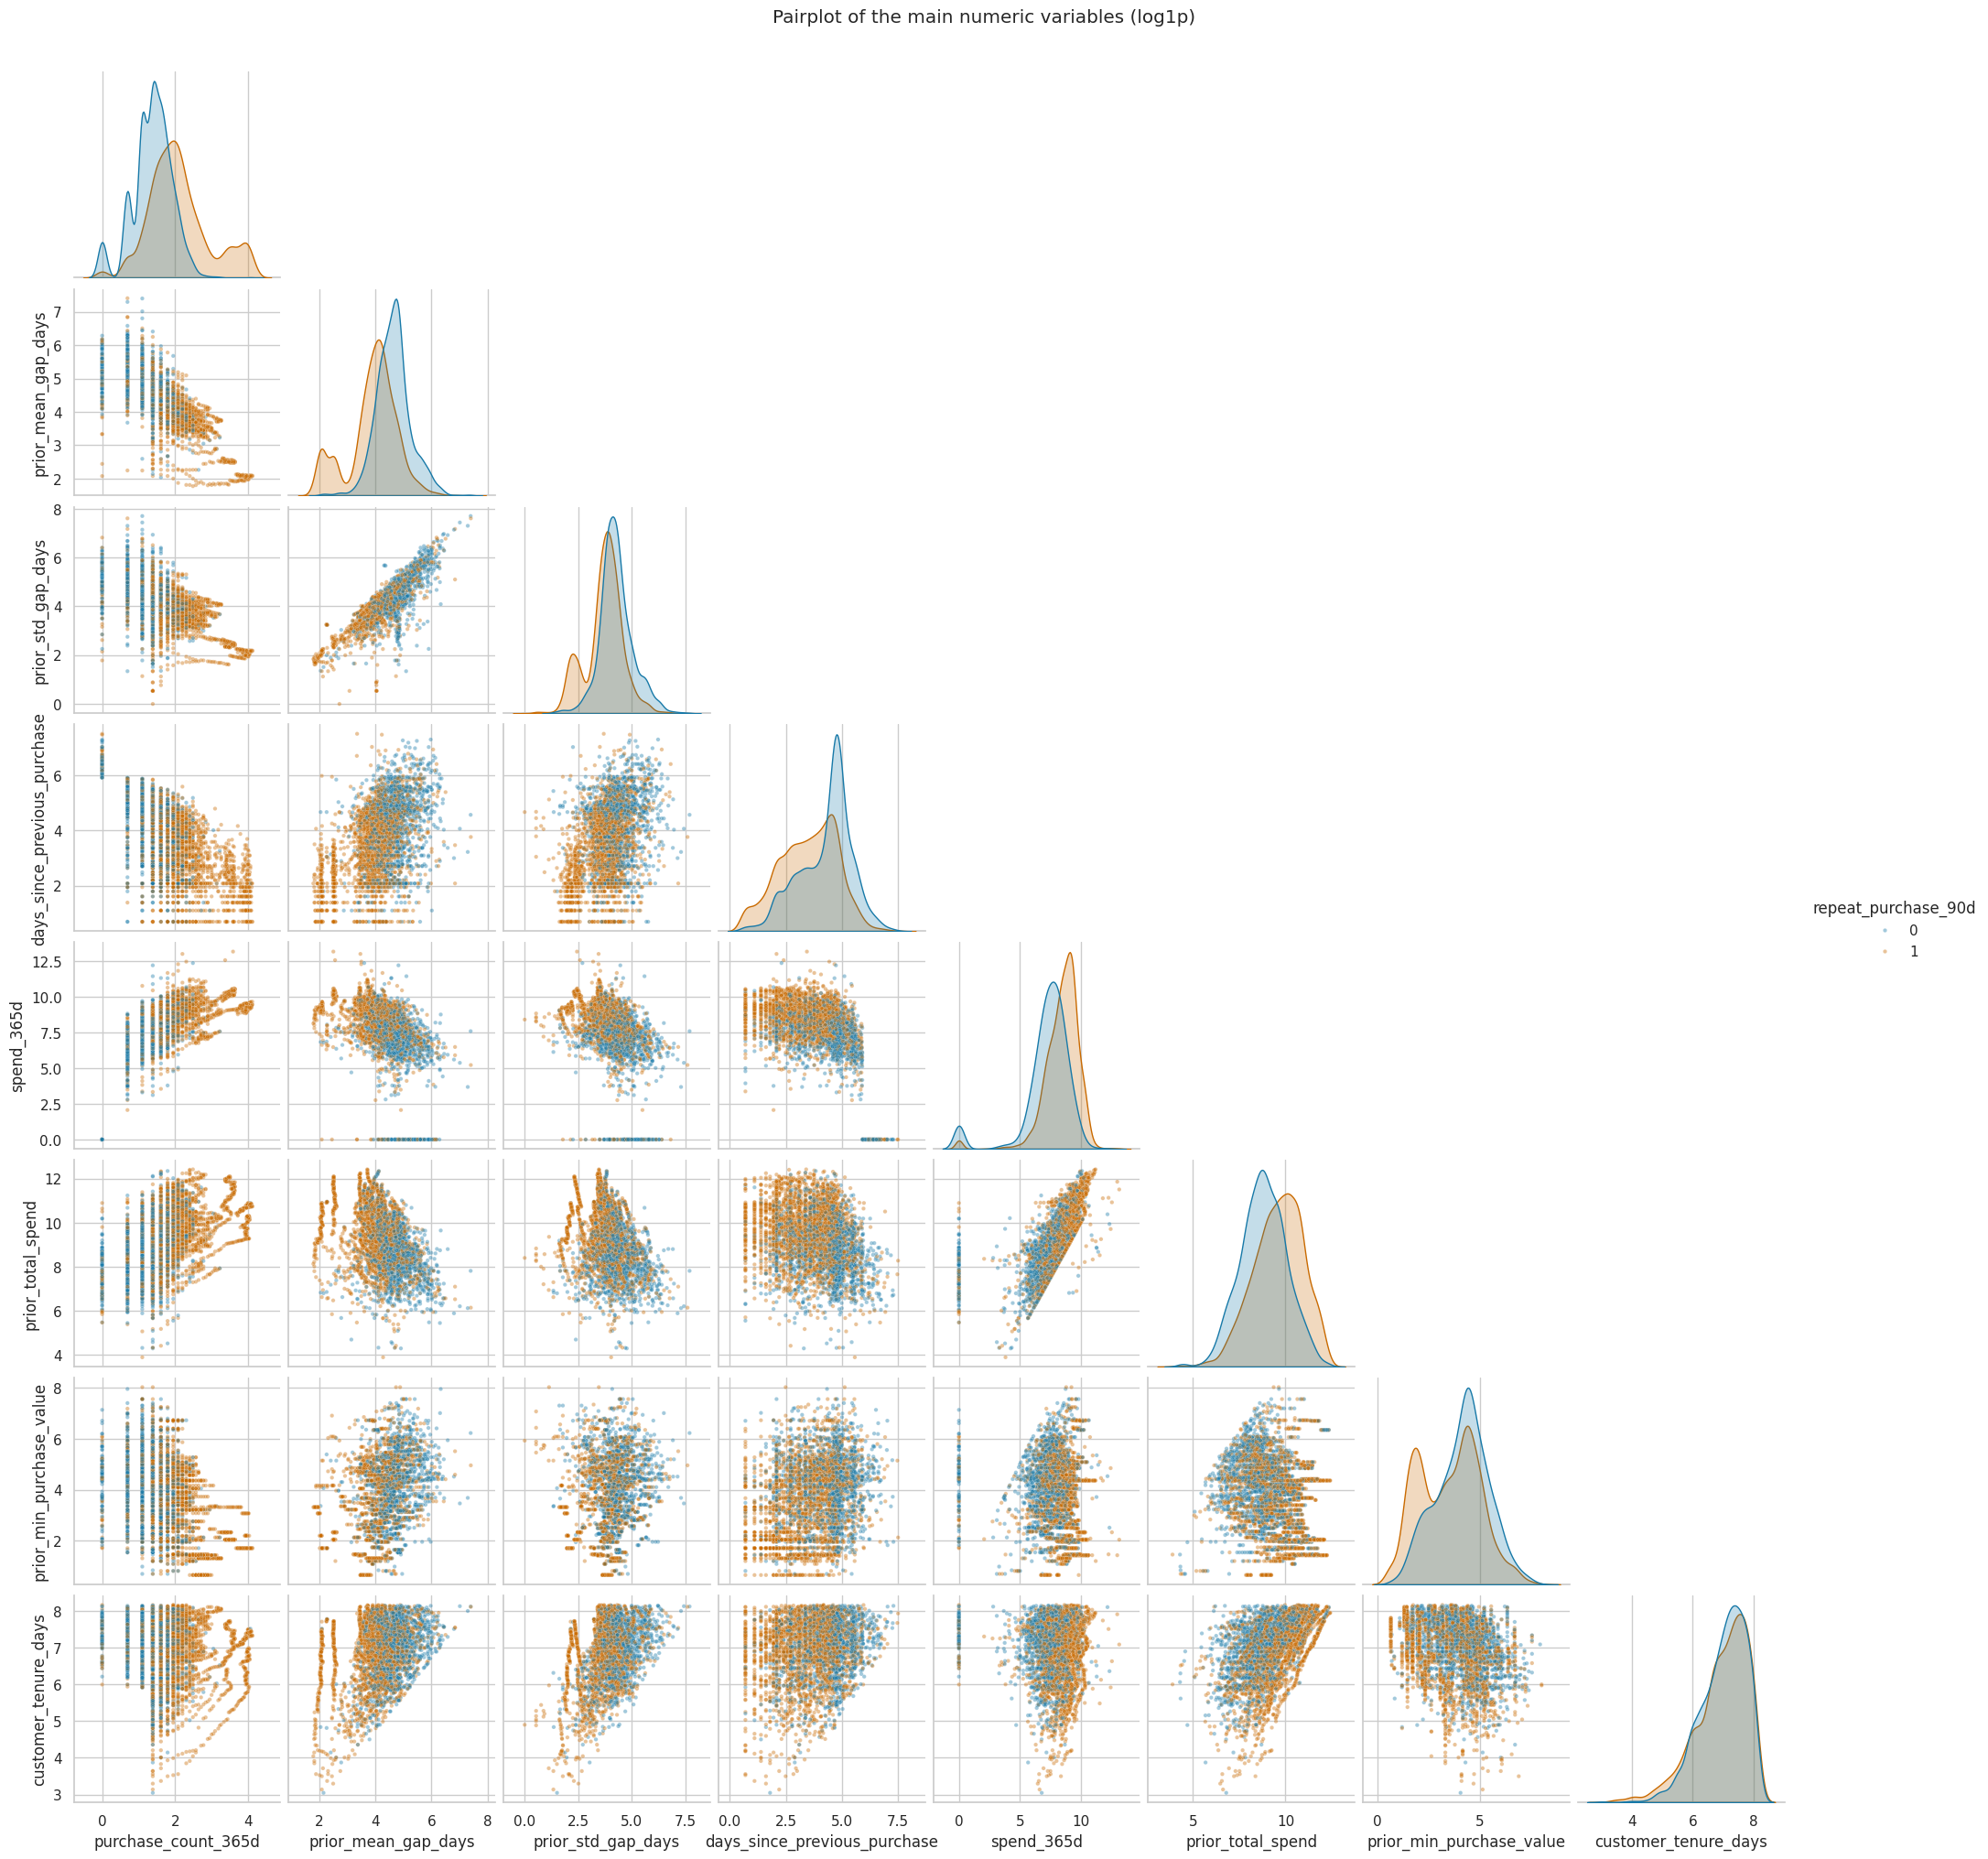

In [83]:
cols = ["purchase_count_365d", "prior_mean_gap_days", "prior_std_gap_days","days_since_previous_purchase", "spend_365d", "prior_total_spend","prior_min_purchase_value", "customer_tenure_days"]

pair_data = np.log1p(clean[cols])
pair_data["repeat_purchase_90d"] = train["repeat_purchase_90d"]

g = sns.pairplot(pair_data.dropna(), hue="repeat_purchase_90d", corner=True,palette=[PLOT_BLUE, PLOT_ORANGE], plot_kws={"s": 10, "alpha": 0.4},diag_kws={"common_norm": False})
g.figure.suptitle("Pairplot of the main numeric variables (log1p)", y=1.02)
plt.show()

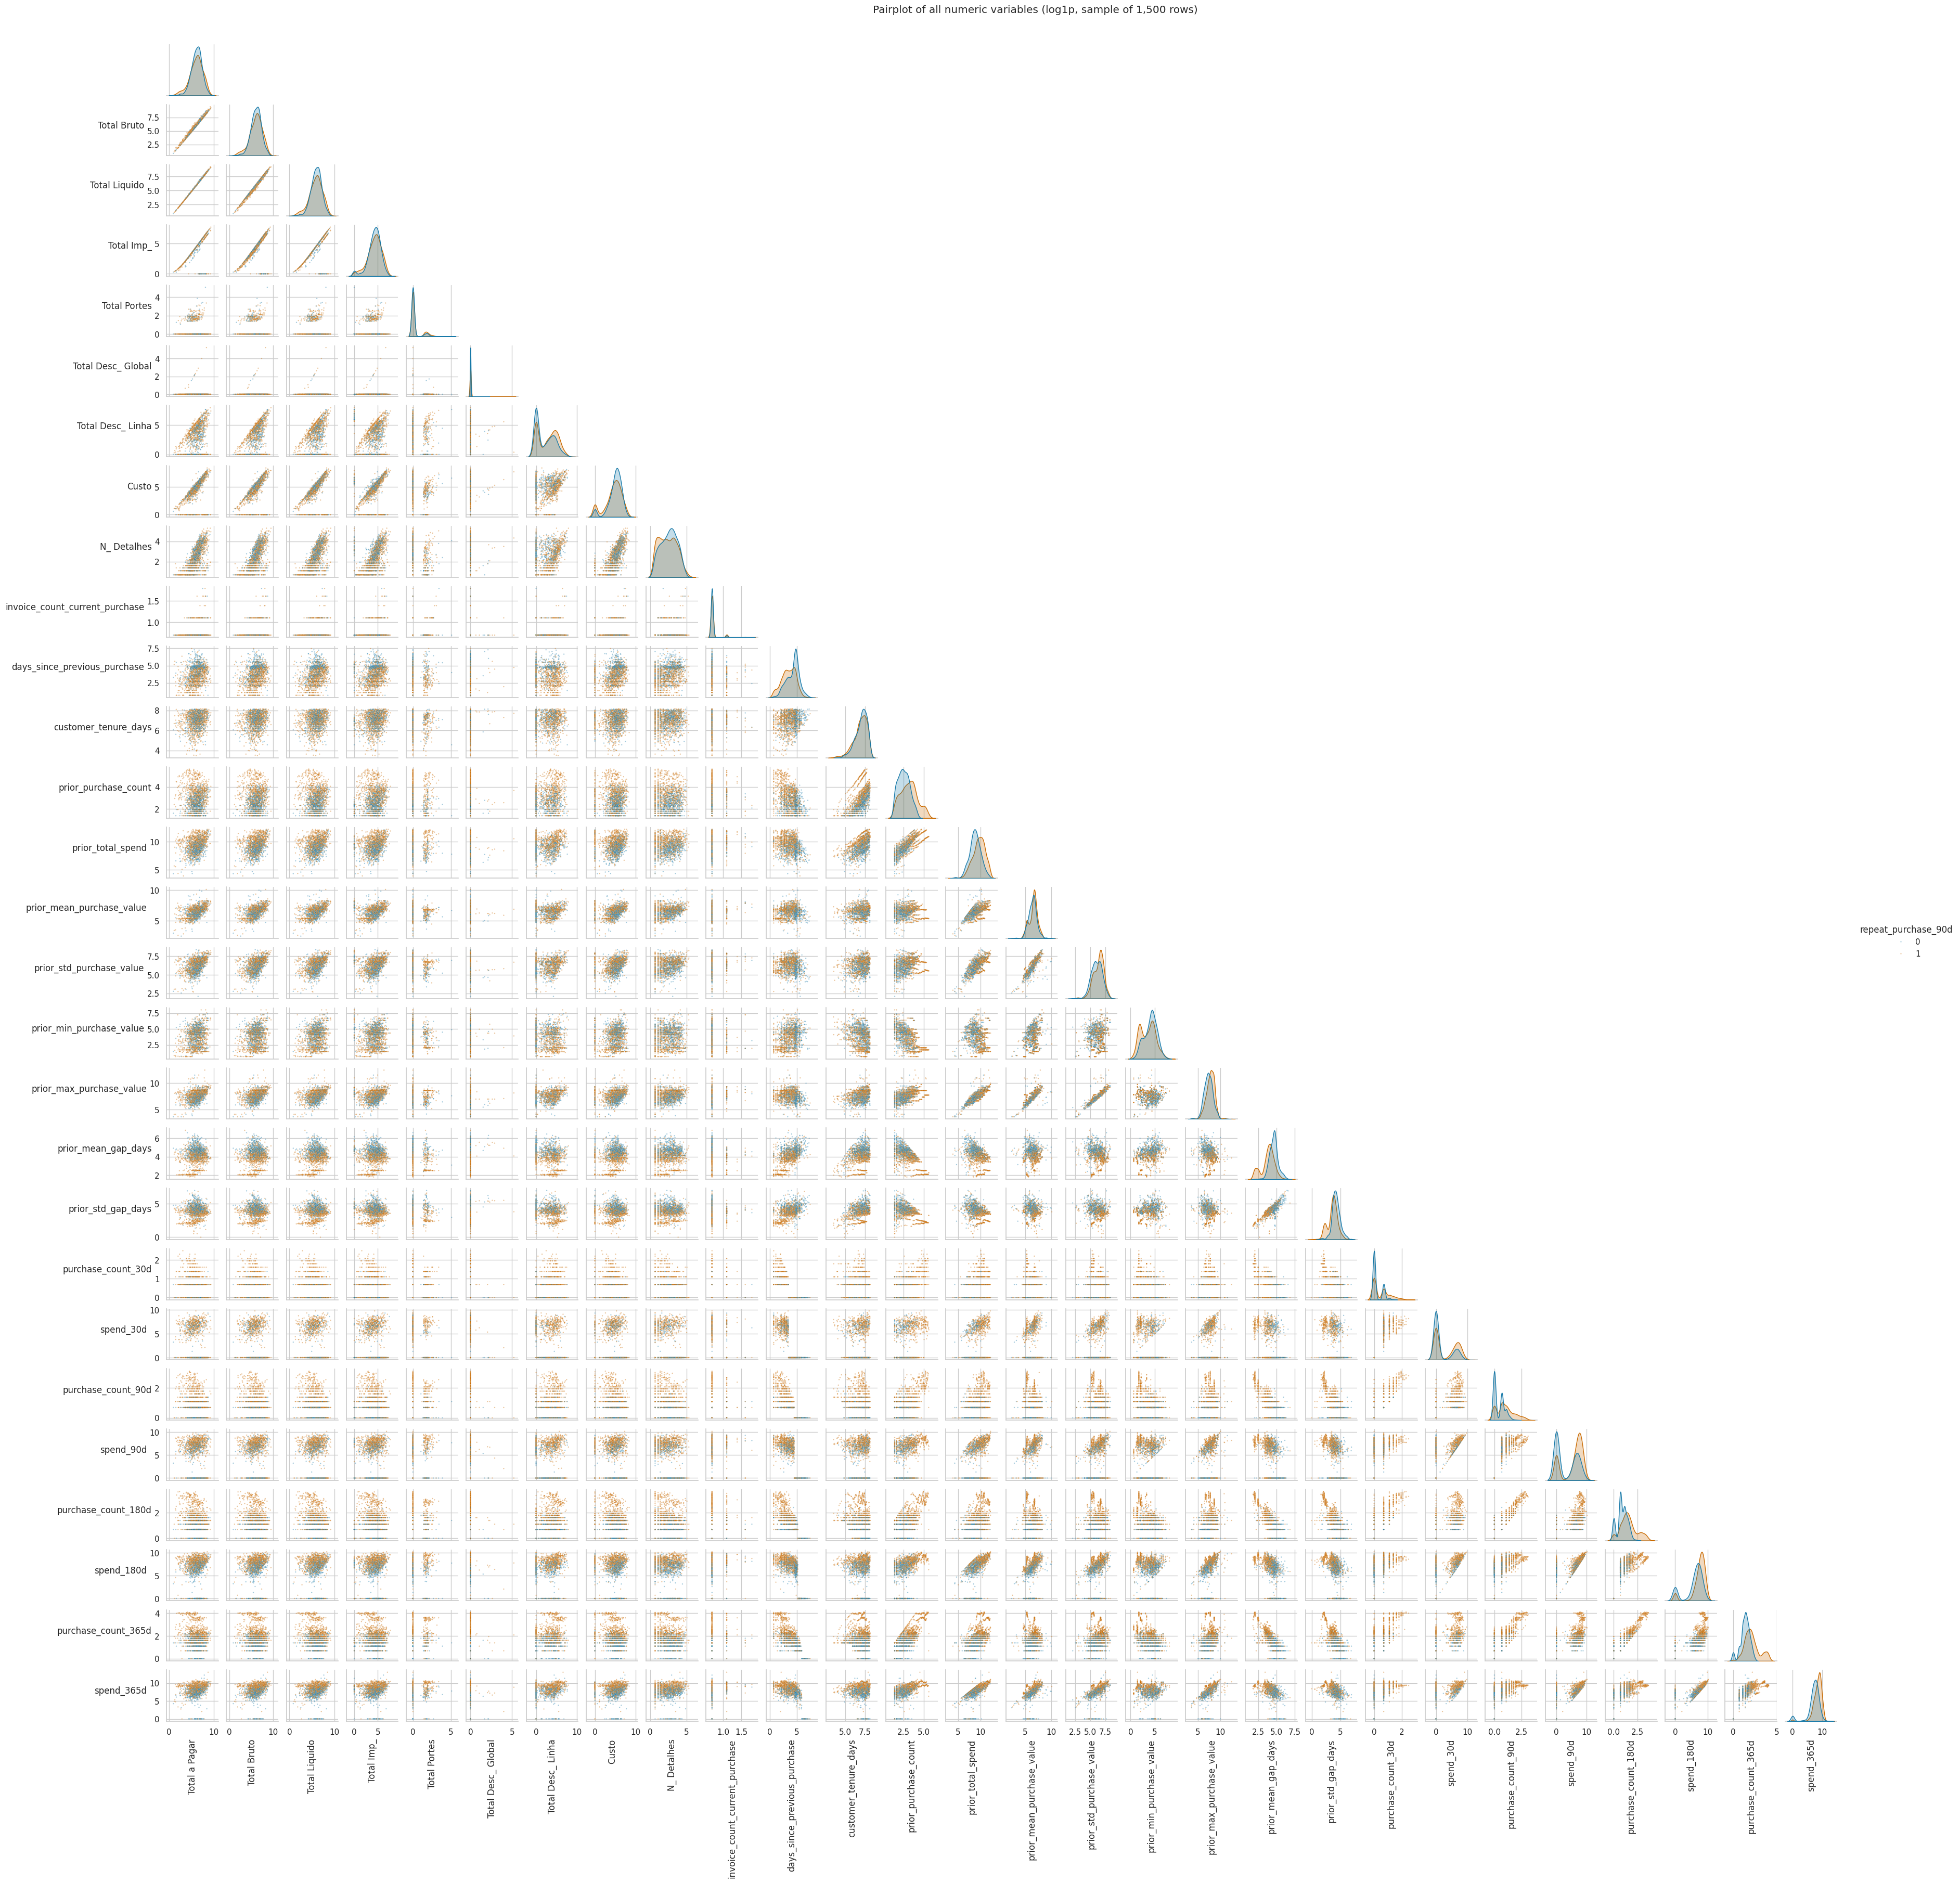

In [84]:
all_cols = list(numeric_cols)

pair_data = np.log1p(clean[all_cols])
pair_data["repeat_purchase_90d"] = train["repeat_purchase_90d"]
pair_sample = pair_data.dropna().sample(1500, random_state=42)

g = sns.pairplot(pair_sample, hue="repeat_purchase_90d", corner=True, height=1.2,
                 palette=[PLOT_BLUE, PLOT_ORANGE], plot_kws={"s": 3, "alpha": 0.4},
                 diag_kws={"common_norm": False})
for ax in g.axes.flatten():
    if ax is not None:
        ax.set_xlabel(ax.get_xlabel(), rotation=90)
        ax.set_ylabel(ax.get_ylabel(), rotation=0, ha="right")
g.figure.suptitle("Pairplot of all numeric variables (log1p, sample of 1,500 rows)", y=1.01)
plt.show()